# EDTA T-ECD

Анализ домена Retail

In [138]:
import os
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

In [139]:
DATASET_PATH = '../../data/T_ECD_Project/raw_data/dataset/small'

## 1. Изучим данные:


Retail — поведение в сервисе доставки продуктов: от просмотра до оформления заказа.

Цены в каталогах переведены в промежуток от −10 до 10. Названия и описания товаров представлены эмбеддингами.

Информация о товарах:

In [140]:
df_retail = pl.read_parquet(os.path.join(DATASET_PATH, 'retail', 'items.pq'))
print(df_retail.head(3))
print(f"Всего товаров в таблице: {len(df_retail)}")

shape: (3, 6)
┌──────────────┬──────────┬────────────────────┬───────────────────┬───────────┬───────────────────┐
│ item_id      ┆ brand_id ┆ category           ┆ subcategory       ┆ price     ┆ embedding         │
│ ---          ┆ ---      ┆ ---                ┆ ---               ┆ ---       ┆ ---               │
│ str          ┆ u64      ┆ str                ┆ str               ┆ f64       ┆ array[f32, 300]   │
╞══════════════╪══════════╪════════════════════╪═══════════════════╪═══════════╪═══════════════════╡
│ fmcg_10      ┆ 65693    ┆ Office Supplies    ┆ Stationery Paper  ┆ -4.426084 ┆ [-0.135573,       │
│              ┆          ┆ and Educationa…    ┆                   ┆           ┆ 0.049446, …       │
│              ┆          ┆                    ┆                   ┆           ┆ 0.0231…           │
│ fmcg_10000   ┆ 146468   ┆ Cleaning Supplies  ┆ Cleaning and      ┆ -4.083248 ┆ [-0.043275,       │
│              ┆          ┆ and Everyday…      ┆ Detergent         ┆         

Анализ пропущенных значений:

Анализ пропусков в Retail Items:
  - item_id: 0 пропусков (0.00%)
  - brand_id: 0 пропусков (0.00%)
  - category: 9,615 пропусков (3.83%)
  - subcategory: 9,615 пропусков (3.83%)
  - price: 725 пропусков (0.29%)
  - embedding: 0 пропусков (0.00%)


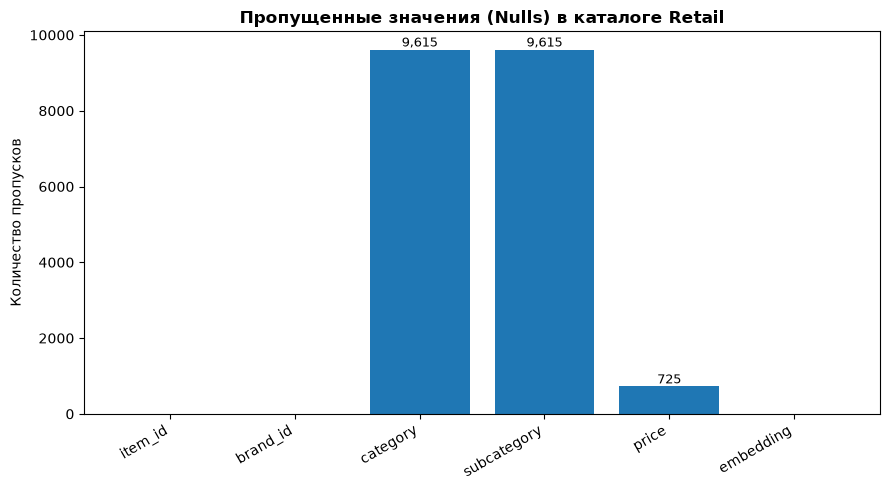

In [141]:
# 1. Считаем количество пропусков по каждому столбцу
null_counts_df = df_retail.select([pl.col(c).null_count().alias(c) for c in df_retail.columns])
null_counts_dict = null_counts_df.row(0, named=True)

# 2. Выводим текстовый отчет с процентами
print("Анализ пропусков в Retail Items:")
total_rows = len(df_retail)
for col, count in null_counts_dict.items():
    pct = (count / total_rows) * 100
    print(f"  - {col}: {count:,} пропусков ({pct:.2f}%)")

# 3. Строим диаграмму
cols = list(null_counts_dict.keys())
counts = list(null_counts_dict.values())

plt.figure(figsize=(9, 5))
bars = plt.bar(cols, counts)

plt.title('Пропущенные значения (Nulls) в каталоге Retail', fontsize=12, fontweight='bold')
plt.ylabel('Количество пропусков')
plt.xticks(rotation=30, ha='right')

# Подписываем точные значения над столбцами, где пропуски есть
for bar in bars:
    height = bar.get_height()
    if height > 0:
        plt.text(bar.get_x() + bar.get_width()/2., height, f'{height:,}',
                 ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

Вывод информация о продуктах имеет пропущенные значения в категории и подкатегории. Идентификатор продуктов, бренд и ембединг заполнены. Продуктовые ембединги позволят находить схожие продукты и строить предсказания без наличия категории и подкатегории.

Данные о брендах:

In [142]:
df_brands = pl.read_parquet(os.path.join(DATASET_PATH, 'brands.pq'))
print(df_brands.head(3))
print(f"Всего товаров в таблице: {len(df_brands)}")

shape: (3, 2)
┌──────────┬─────────────────┐
│ brand_id ┆ embedding       │
│ ---      ┆ ---             │
│ u64      ┆ array[f32, 300] │
╞══════════╪═════════════════╡
│ 4        ┆ null            │
│ 34       ┆ null            │
│ 45       ┆ null            │
└──────────┴─────────────────┘
Всего товаров в таблице: 29485


In [143]:
retail_brands = df_retail.select(pl.col('brand_id').unique()).get_column('brand_id')
print(f"Всего уникальных брендов в товарах ритейла (items.pq): {len(retail_brands):,}")

catalog_brands = df_brands.get_column('brand_id')

in_retail_not_in_catalog = df_retail.filter(~pl.col('brand_id').is_in(list(catalog_brands)))
print(f"Товары, ссылающиеся на несуществующие в справочнике бренды: {len(in_retail_not_in_catalog):,}")

Всего уникальных брендов в товарах ритейла (items.pq): 8
Товары, ссылающиеся на несуществующие в справочнике бренды: 0


Все товары имеют бренды из каталога

Взаимодействия user × item:

In [144]:
events_path = os.path.join(DATASET_PATH, 'retail', 'events')
events_files = os.listdir(events_path)
print(f"Всего файлов в папке events: {len(events_files)}")


Всего файлов в папке events: 227


In [145]:
df_events_01082 = pl.read_parquet(os.path.join(DATASET_PATH, 'retail', 'events', '01082.pq'))
print(df_events_01082.head(3))
print(f"Данные за один день 01082: {len(df_events_01082)}")

shape: (3, 6)
┌────────────────┬──────────┬─────────────┬───────────┬─────────────┬─────────┐
│ timestamp      ┆ user_id  ┆ item_id     ┆ subdomain ┆ action_type ┆ os      │
│ ---            ┆ ---      ┆ ---         ┆ ---       ┆ ---         ┆ ---     │
│ duration[μs]   ┆ u64      ┆ str         ┆ str       ┆ str         ┆ str     │
╞════════════════╪══════════╪═════════════╪═══════════╪═════════════╪═════════╡
│ 1082d 188968µs ┆ 61870822 ┆ fmcg_292242 ┆ search    ┆ view        ┆ android │
│ 1082d 237416µs ┆ 6411253  ┆ fmcg_761291 ┆ catalog   ┆ view        ┆ android │
│ 1082d 240923µs ┆ 15367638 ┆ fmcg_830525 ┆ catalog   ┆ view        ┆ android │
└────────────────┴──────────┴─────────────┴───────────┴─────────────┴─────────┘
Данные за один день 01082: 387302


Информация о пользователях:

In [146]:
df_users = pl.read_parquet(os.path.join(DATASET_PATH, 'users.pq'))
print(df_users.head(3))
print(f"Всего пользователей в таблице: {len(df_users)}")

shape: (3, 3)
┌──────────┬────────────────┬────────┐
│ user_id  ┆ socdem_cluster ┆ region │
│ ---      ┆ ---            ┆ ---    │
│ u64      ┆ u8             ┆ u8     │
╞══════════╪════════════════╪════════╡
│ 77309558 ┆ 21             ┆ 2      │
│ 72517894 ┆ 10             ┆ 90     │
│ 86699708 ┆ 9              ┆ 9      │
└──────────┴────────────────┴────────┘
Всего пользователей в таблице: 3500000


In [147]:
user_nulls = df_users.select([pl.col(c).null_count().alias(c) for c in df_users.columns])
print("Пропуски в users.pq:")
print(user_nulls)

user_nulls_length = len(df_users)

for col in df_users.columns:
    cnt = user_nulls[0, col]
    pct = (cnt / user_nulls_length) * 100
    print(f"  - {col}: {cnt:,} пропусков ({pct:.2f}%)")


Пропуски в users.pq:
shape: (1, 3)
┌─────────┬────────────────┬────────┐
│ user_id ┆ socdem_cluster ┆ region │
│ ---     ┆ ---            ┆ ---    │
│ u32     ┆ u32            ┆ u32    │
╞═════════╪════════════════╪════════╡
│ 0       ┆ 5153           ┆ 58917  │
└─────────┴────────────────┴────────┘
  - user_id: 0 пропусков (0.00%)
  - socdem_cluster: 5,153 пропусков (0.15%)
  - region: 58,917 пропусков (1.68%)


Анализ регионов и кластеров:

In [148]:
top_regions = df_users.group_by('region').len().sort('len', descending=True)
top_clusters = df_users.group_by('socdem_cluster').len().sort('len', descending=True)

print("Топ-5 регионов по количеству пользователей:")
print(top_regions.head(5))

print("\nТоп-5 социодемографических кластеров:")
print(top_clusters.head(5))

Топ-5 регионов по количеству пользователей:
shape: (5, 2)
┌────────┬────────┐
│ region ┆ len    │
│ ---    ┆ ---    │
│ u8     ┆ u32    │
╞════════╪════════╡
│ 2      ┆ 551358 │
│ 60     ┆ 249920 │
│ 90     ┆ 181623 │
│ 18     ┆ 137250 │
│ 24     ┆ 114992 │
└────────┴────────┘

Топ-5 социодемографических кластеров:
shape: (5, 2)
┌────────────────┬────────┐
│ socdem_cluster ┆ len    │
│ ---            ┆ ---    │
│ u8             ┆ u32    │
╞════════════════╪════════╡
│ 17             ┆ 473629 │
│ 20             ┆ 420944 │
│ 12             ┆ 416287 │
│ 9              ┆ 340144 │
│ 21             ┆ 331140 │
└────────────────┴────────┘


Пропуски в events (по всем 227 файлам):

In [149]:
events_pattern = os.path.join(DATASET_PATH, 'retail', 'events', '*.pq')
lazy_events = pl.scan_parquet(events_pattern)

In [150]:
event_cols = ['timestamp', 'user_id', 'item_id', 'subdomain', 'action_type', 'os']
event_nulls = lazy_events.select([pl.col(c).null_count().alias(c) for c in event_cols]).collect()
print("\nПропуски во всех файлах events (Retail):")
print(event_nulls)


Пропуски во всех файлах events (Retail):
shape: (1, 6)
┌───────────┬─────────┬─────────┬───────────┬─────────────┬─────┐
│ timestamp ┆ user_id ┆ item_id ┆ subdomain ┆ action_type ┆ os  │
│ ---       ┆ ---     ┆ ---     ┆ ---       ┆ ---         ┆ --- │
│ u32       ┆ u32     ┆ u32     ┆ u32       ┆ u32         ┆ u32 │
╞═══════════╪═════════╪═════════╪═══════════╪═════════════╪═════╡
│ 0         ┆ 0       ┆ 0       ┆ 0         ┆ 0           ┆ 0   │
└───────────┴─────────┴─────────┴───────────┴─────────────┴─────┘


## 2. Изучение признаков

Собираем уникальных юзеров из логов событий:

In [151]:
unique_event_users = lazy_events.select(pl.col('user_id')).unique().collect().get_column('user_id')
catalog_users = df_users.get_column('user_id')

Ищем тех, кто есть в событиях, но отсутствует в users.pq:

In [152]:
orphaned_event_users = unique_event_users.filter(~unique_event_users.is_in(catalog_users.implode()))
print(f"Уникальных пользователей в событиях: {len(unique_event_users):,}")
print(f"Пользователей из событий, отсутствующих в users.pq: {len(orphaned_event_users):,}")

Уникальных пользователей в событиях: 140,062
Пользователей из событий, отсутствующих в users.pq: 0


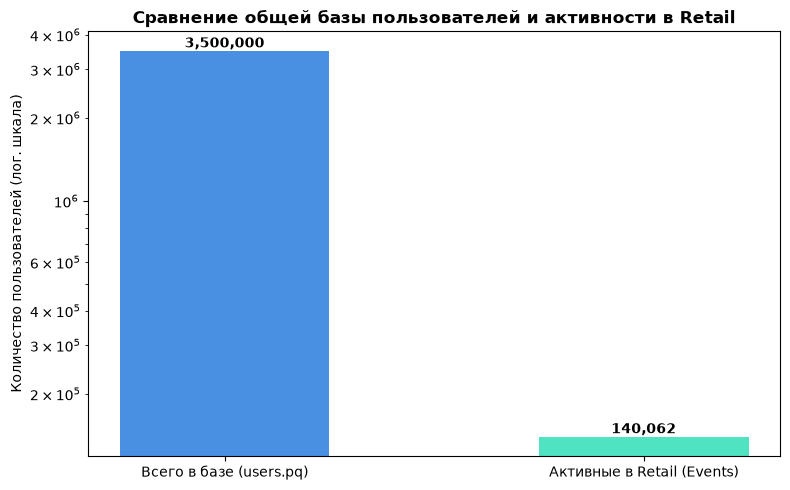

In [153]:
# Данные для графика
total_users = len(df_users)  # 3,500,000
retail_active_users = len(unique_event_users)

categories = ['Всего в базе (users.pq)', 'Активные в Retail (Events)']
counts = [total_users, retail_active_users]

plt.figure(figsize=(8, 5))
bars = plt.bar(categories, counts, color=['#4A90E2', '#50E3C2'], width=0.5)

plt.title('Сравнение общей базы пользователей и активности в Retail', fontsize=12, fontweight='bold')
plt.ylabel('Количество пользователей')

# Добавляем подقписи точных значений над столбцами
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height, f'{height:,}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# Логарифмическая шкала здесь полезна, так как разница в масштабе большая
plt.yscale('log')
plt.ylabel('Количество пользователей (лог. шкала)')

plt.tight_layout()
plt.show()

Уникальные категории в событиях (subdomain, action_type, os)

In [154]:
subdomains = lazy_events.select(pl.col('subdomain').unique()).collect().get_column('subdomain').to_list()
action_types = lazy_events.select(pl.col('action_type').unique()).collect().get_column('action_type').to_list()
os_types = lazy_events.select(pl.col('os').unique()).collect().get_column('os').to_list()

print(f"subdomain: {subdomains}")
print(f"action_type: {action_types}")
print(f"os: {os_types}")

subdomain: ['other', 'catalog', 'search', 'main', 'i2i']
action_type: ['click', 'added_to_cart', 'view', 'order']
os: ['other', 'android', 'ios']


Анализ subdomain:

In [155]:
subdomain_counts = lazy_events.group_by('subdomain').len().sort('len', descending=True).collect()

print("Статистика событий по subdomain:")
print(subdomain_counts)

Статистика событий по subdomain:
shape: (5, 2)
┌───────────┬───────────┐
│ subdomain ┆ len       │
│ ---       ┆ ---       │
│ str       ┆ u32       │
╞═══════════╪═══════════╡
│ catalog   ┆ 231285386 │
│ search    ┆ 21575005  │
│ other     ┆ 7433721   │
│ main      ┆ 3804123   │
│ i2i       ┆ 2945737   │
└───────────┴───────────┘


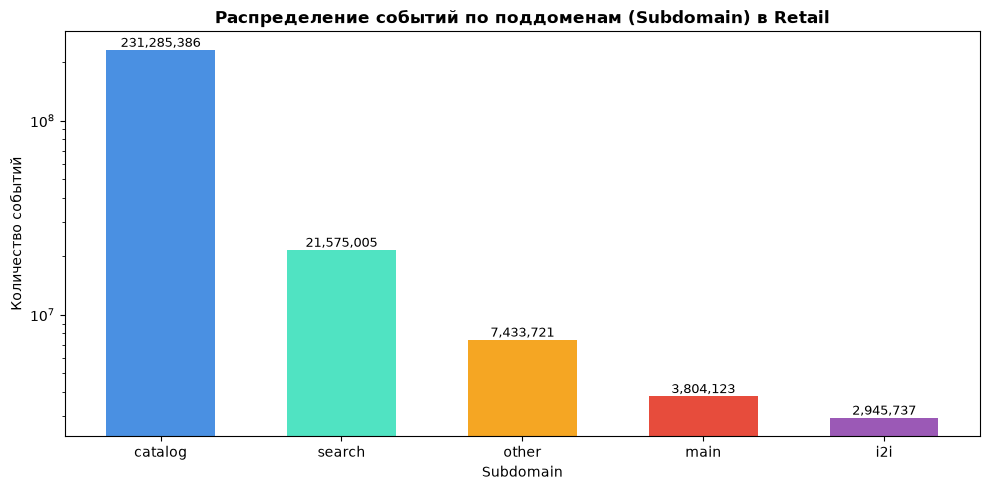

In [156]:
# Достаем данные из результатов группировки
subdomains = subdomain_counts.get_column('subdomain').to_list()
counts = subdomain_counts.get_column('len').to_list()

# Набор красивых уникальных цветов для каждого поддомена
colors = ['#4A90E2', '#50E3C2', '#F5A623', '#E74C3C', '#9B59B6']

plt.figure(figsize=(10, 5))
bars = plt.bar(subdomains, counts, color=colors[:len(subdomains)], width=0.6)

plt.title('Распределение событий по поддоменам (Subdomain) в Retail', fontsize=12, fontweight='bold')
plt.ylabel('Количество событий')
plt.yscale('log')
plt.xlabel('Subdomain')

# Подписываем точные значения над столбцами
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height, f'{height:,.0f}',
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

Анализ action_type:

In [157]:
action_type_counts = lazy_events.group_by('action_type').len().sort('len', descending=True).collect()

print("Статистика событий по action_type:")
print(action_type_counts)

Статистика событий по action_type:
shape: (4, 2)
┌───────────────┬───────────┐
│ action_type   ┆ len       │
│ ---           ┆ ---       │
│ str           ┆ u32       │
╞═══════════════╪═══════════╡
│ view          ┆ 253468410 │
│ order         ┆ 7433721   │
│ added_to_cart ┆ 3852145   │
│ click         ┆ 2289696   │
└───────────────┴───────────┘


Просмотров - 253 468 410

Заказов - 7 433 721

Добавлено в корзину - 3 852 145

Кликов - 2 289 696

В ритейле заказов больше чем добавлений в корзину и кликов.


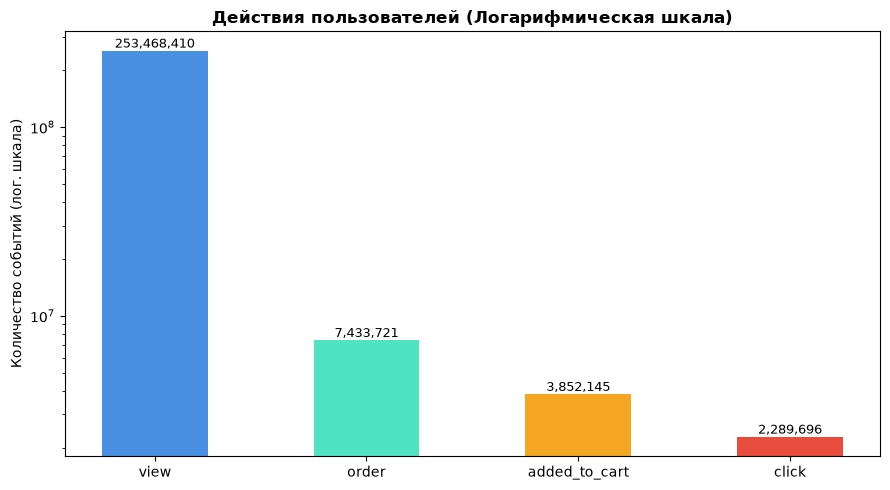

In [158]:
# Данные
actions = action_type_counts.get_column('action_type').to_list()
counts = action_type_counts.get_column('len').to_list()

# Строим график в логарифмической шкале
plt.figure(figsize=(9, 5))
bars = plt.bar(actions, counts, color=['#4A90E2', '#50E3C2', '#F5A623', '#E74C3C'], width=0.5)

plt.title('Действия пользователей (Логарифмическая шкала)', fontsize=12, fontweight='bold')
plt.ylabel('Количество событий (лог. шкала)')
plt.yscale('log')  # Смягчаем гигантский разрыв view

# Подписываем точные значения над столбцами
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height, f'{height:,.0f}',
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


In [159]:
os_counts = lazy_events.group_by('os').len().sort('len', descending=True).collect()

print("Статистика событий по os:")
print(os_counts)

Статистика событий по os:
shape: (3, 2)
┌─────────┬───────────┐
│ os      ┆ len       │
│ ---     ┆ ---       │
│ str     ┆ u32       │
╞═════════╪═══════════╡
│ android ┆ 242432816 │
│ ios     ┆ 22007523  │
│ other   ┆ 2603633   │
└─────────┴───────────┘


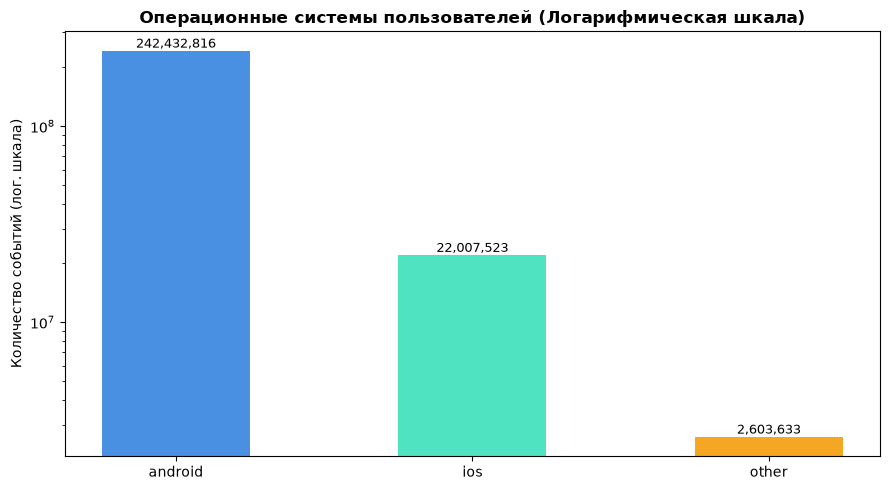

In [160]:
# Данные
os_names = os_counts.get_column('os').to_list()
counts = os_counts.get_column('len').to_list()

# Строим график в логарифмической шкале
plt.figure(figsize=(9, 5))
bars = plt.bar(os_names, counts, color=['#4A90E2', '#50E3C2', '#F5A623',], width=0.5)

plt.title('Операционные системы пользователей (Логарифмическая шкала)', fontsize=12, fontweight='bold')
plt.ylabel('Количество событий (лог. шкала)')
plt.yscale('log')  # Смягчаем гигантский разрыв view

# Подписываем точные значения над столбцами
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height, f'{height:,.0f}',
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


In [161]:
# Группируем по пользователям и считаем количество событий на каждого
user_activity = lazy_events.group_by('user_id').len().rename({'len': 'event_count'}).collect()
counts = user_activity.get_column('event_count').to_list()

# Вычисляем ключевую статистику
print("Статистика количества событий на пользователя:")
print(user_activity.select([
    pl.col('event_count').min().alias('min_events'),
    pl.col('event_count').quantile(0.25).alias('q25'),
    pl.col('event_count').median().alias('median_events'),
    pl.col('event_count').mean().alias('mean_events'),
    pl.col('event_count').quantile(0.75).alias('q75'),
    pl.col('event_count').max().alias('max_events'),
]))

Статистика количества событий на пользователя:
shape: (1, 6)
┌────────────┬──────┬───────────────┬─────────────┬───────┬────────────┐
│ min_events ┆ q25  ┆ median_events ┆ mean_events ┆ q75   ┆ max_events │
│ ---        ┆ ---  ┆ ---           ┆ ---         ┆ ---   ┆ ---        │
│ u32        ┆ f64  ┆ f64           ┆ f64         ┆ f64   ┆ u32        │
╞════════════╪══════╪═══════════════╪═════════════╪═══════╪════════════╡
│ 1          ┆ 10.0 ┆ 61.0          ┆ 1906.612586 ┆ 587.0 ┆ 92615      │
└────────────┴──────┴───────────────┴─────────────┴───────┴────────────┘


Миниальное кол-во событий - 1

Максимальное - 92 615

Можно предположить наличие ботов и парсеров

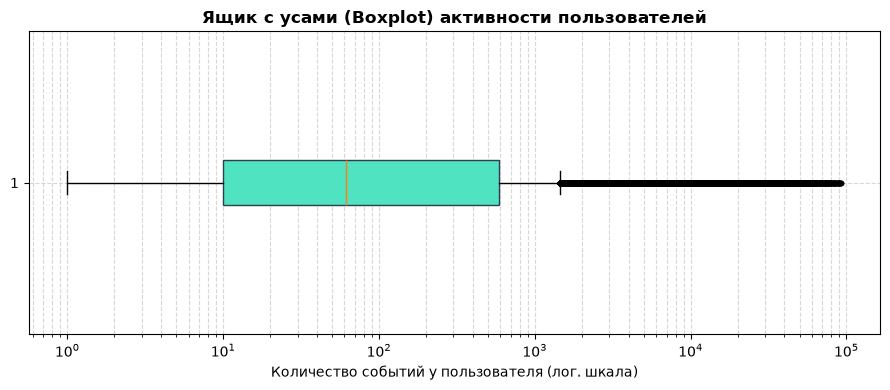

In [162]:
plt.figure(figsize=(9, 4))
plt.boxplot(counts, orientation='horizontal', patch_artist=True,
            boxprops=dict(facecolor='#50E3C2', color='#2C3E50'),
            flierprops=dict(marker='o', color='red', alpha=0.3, markersize=3))

plt.title('Ящик с усами (Boxplot) активности пользователей', fontsize=12, fontweight='bold')
plt.xlabel('Количество событий у пользователя (лог. шкала)')
plt.xscale('log')  # Обязательно лог-шкала из-за огромного размаха
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [163]:
# Группируем по товарам и считаем суммарное количество событий на каждый item_id
item_activity = lazy_events.group_by('item_id').len().rename({'len': 'event_count'}).sort('event_count', descending=True).collect()

# Выводим базовую статистику
print("Статистика событий по товарам:")
print(item_activity.select([
    pl.col('event_count').min().alias('min_events'),
    pl.col('event_count').quantile(0.25).alias('q25'),
    pl.col('event_count').median().alias('median_events'),
    pl.col('event_count').mean().alias('mean_events'),
    pl.col('event_count').quantile(0.75).alias('q75'),
    pl.col('event_count').max().alias('max_events'),
]))


Статистика событий по товарам:
shape: (1, 6)
┌────────────┬──────┬───────────────┬─────────────┬───────┬────────────┐
│ min_events ┆ q25  ┆ median_events ┆ mean_events ┆ q75   ┆ max_events │
│ ---        ┆ ---  ┆ ---           ┆ ---         ┆ ---   ┆ ---        │
│ u32        ┆ f64  ┆ f64           ┆ f64         ┆ f64   ┆ u32        │
╞════════════╪══════╪═══════════════╪═════════════╪═══════╪════════════╡
│ 1          ┆ 16.0 ┆ 102.0         ┆ 1037.761183 ┆ 555.0 ┆ 320414     │
└────────────┴──────┴───────────────┴─────────────┴───────┴────────────┘


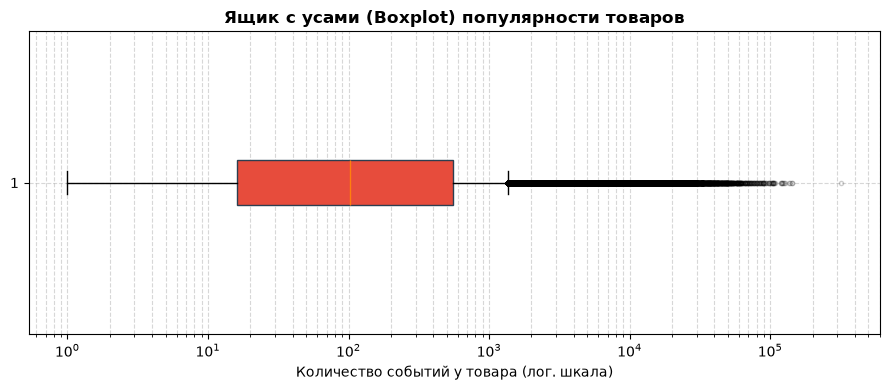

In [164]:
# 1. Берем распределение событий по товарам (если еще не в памяти)
counts = item_activity.get_column('event_count').to_list()

# 2. Строим горизонтальный boxplot
plt.figure(figsize=(9, 4))
plt.boxplot(counts, orientation='horizontal', patch_artist=True,
            boxprops=dict(facecolor='#E74C3C', color='#2C3E50'),
            flierprops=dict(marker='o', color='blue', alpha=0.2, markersize=3))

plt.title('Ящик с усами (Boxplot) популярности товаров', fontsize=12, fontweight='bold')
plt.xlabel('Количество событий у товара (лог. шкала)')
plt.xscale('log')  # Смягчаем огромный размах от 1 до 320k
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 3. Вывод

* Высокое качество датасета. Пропусков очень мало, пропущенных эмбедингов в товарах нет, что позволит произвести анализ без категорий и подкатегорий. Все товары из событий имеют бренд из таблицы brands, и все пользователи есть в таблице users.

* Большое кол-во событий у пользователей - 92 615 выглядит подозрительно. Необходимо отфильтровывать пользователей с подозрительно большой активностью.

* Есть товары на долю которых приходится 320 414 событий а есть товары на долю которых приходится 1 событие. Нужно учитывать этот факт и применить регуляризацию.

* Особенность покупок в Retail - покупок больше чем кликов и добавлений в корзину

* Мобильный профиль аудитории - доминирует платформа android, вторая - ios